# Export - tables of layer 4

The clinical indices of layer 3 as tables for R, SPSS, Excel and databases (`fasteit.export`), on the recordings of
notebook 07: 11 tidal recordings and four decremental PEEP trials (patients A and B, supine and park bench). The guide
is `docs/export.md`.

| § | Content |
|---|---------|
| 1 | One analysis: a tidal recording |
| 2 | A PEEP trial, with the PEEP levels of the protocol |
| 3 | A study, and a recording with two phases |
| 4 | Wide and long: one row per patient, regions as rows, curves of the trial |
| 5 | CSV files |

The recordings are not in the repository.

*Research use only - not a medical device.*

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from fasteit.config import SegmentationConfig
from fasteit.export import KEYS, combine_tables, recording_tables, write_csv
from fasteit.features import peep_trial_features, tidal_features
from fasteit.models import RecordingContext, Segment
from fasteit.parsers.loader import load_data
from fasteit.preprocessing import preprocess
from fasteit.segmentation import segment_peep_trial

TEST_FILES = Path("../src/fasteit/test_files")
TIDAL_FILES = sorted(p for p in TEST_FILES.glob("*.bin") if "PEEP_trial" not in p.name)
TRIAL_FILES = sorted(TEST_FILES.glob("*PEEP_trial*.bin"))
SET_VT = {"A": 550, "B": 400}  # mL, set in volume control
PROTOCOL = SegmentationConfig(peep_levels=(16, 14, 12, 10, 8, 6, 4, 2, 0))  # decremental, steps of 2

BLUE, ORANGE, GREY = "#3987e5", "#e8730c", "#9a9a9a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "font.size": 9})
pd.set_option("display.precision", 2)


def tidal_keys(path):
    """patient01_rec03 -> patient01, rec03 (the files without _rec are the first recording)."""
    patient, _, number = path.stem.partition("_rec")
    return patient, f"rec{number}" if number else "rec01"

## 1. One analysis: a tidal recording

The patient and the recording are typed in `RecordingContext` (`patient_id`, `label`); `recording_tables()` gives the
tables of the analysis, every row starting with `patient_id`, `label` and `phase` (by default the protocol).

In [2]:
patient, label = tidal_keys(TEST_FILES / "patient01_rec03.bin")
recording = preprocess(load_data(TEST_FILES / "patient01_rec03.bin"),
                       context=RecordingContext(patient_id=patient, label=label))
tidal_example = tidal_features(recording)
one = recording_tables(tidal_example)
pd.DataFrame({name: table.shape for name, table in one.items()}, index=["rows", "columns"])

,recordings,breaths,settings,log
rows,1,55,20,10
columns,14,55,6,5


`breaths`: one row per breath with times, quality, pressures (layer 2) and indices (layer 3); the regional values
are columns `{index}__{region}`. `used` marks the breaths that entered the indices (the valid breaths of the phase).

In [3]:
columns = KEYS + ["breath_id", "start_time", "is_valid", "used", "peep", "driving_pressure",
                  "eeli", "tiv", "gi", "tiv__ventral", "tiv__dorsal"]
one["breaths"][columns].head()

,patient_id,label,phase,breath_id,start_time,is_valid,used,peep,driving_pressure,eeli,tiv,gi,tiv__ventral,tiv__dorsal
0,patient01,rec03,tidal,0,2.06,True,True,12.24,2.88,451.16,3292.19,0.42,1258.11,2034.08
1,patient01,rec03,tidal,1,3.98,True,True,11.94,4.43,351.87,3262.81,0.42,1244.99,2017.82
2,patient01,rec03,tidal,2,5.88,True,True,12.23,3.20,389.71,3281.95,0.40,1301.99,1979.96
3,patient01,rec03,tidal,3,7.68,True,True,12.25,3.62,507.65,3306.27,0.43,1240.95,2065.32
4,patient01,rec03,tidal,4,9.48,True,True,12.06,3.94,548.46,3181.52,0.44,1171.55,2009.97


`recordings`: one row per analysis, the file and its breaths (the medians are made from `breaths`, §4).

In [4]:
one["recordings"].T

,0
patient_id,patient01
label,rec03
phase,tidal
protocol,tidal
file,patient01_rec03.bin
vendor,draeger
fs,50.0
start_time,2.06
end_time,113.36
n_breaths,55


## 2. A PEEP trial, with the PEEP levels of the protocol

`SegmentationConfig(peep_levels=...)` gives each step `peep_set`, the nearest level of the protocol; `peep` stays the
measured one (cmH2O; 10 mbar set on a Dräger ventilator is 10.2 cmH2O). The step table is the curve of the trial:
layer 2b (level, breaths analysed, driving pressure, tidal volume) and layer 3 (compliance, Costa) in one row.

In [5]:
trials = {}
for path in TRIAL_FILES:
    patient, position = path.stem.replace("PEEP_trial_", "").split("_", 1)
    context = RecordingContext(patient_id=patient, label=position, protocol="peep_trial",
                               tidal_volume_ml=SET_VT[patient])
    trial = segment_peep_trial(preprocess(load_data(path), context=context), PROTOCOL)
    features = peep_trial_features(trial)
    trials[(patient, position)] = recording_tables(features)
    if (patient, position) == ("A", "supine"):
        trial_example = features

The step table:

In [6]:
steps = trials[("A", "supine")]["steps"]
steps[["step", "peep", "peep_set", "n_analysed", "driving_pressure", "tidal_volume", "compliance_ml",
       "compliance_pct_of_best", "collapse", "overdistension"]]

,step,peep,peep_set,n_analysed,driving_pressure,tidal_volume,compliance_ml,compliance_pct_of_best,collapse,overdistension
0,0,16.27,16.0,10,7.99,550.0,68.86,77.87,0.00,35.59
1,1,14.28,14.0,6,7.67,550.0,71.75,82.78,0.62,30.85
2,2,12.27,12.0,7,7.27,550.0,75.70,88.78,1.55,25.13
3,3,10.23,10.0,8,6.93,550.0,79.32,93.93,3.28,19.03
4,4,8.19,8.0,7,6.88,550.0,79.97,94.55,7.08,14.72
5,5,6.16,6.0,6,6.44,550.0,85.41,100.00,9.79,7.52
6,6,4.21,4.0,9,6.65,550.0,82.72,95.52,16.92,4.07
7,7,2.25,2.0,6,6.84,550.0,80.38,90.36,23.93,1.12
8,8,0.47,0.0,10,7.39,550.0,74.40,81.95,31.66,0.00


## 3. A study, and a recording with two phases

A study is the same call on every analysis: `combine_tables()` puts the rows together and refuses two analyses with the
same keys.

In [7]:
analyses = []
for path in TIDAL_FILES:
    patient, label = tidal_keys(path)
    recording = preprocess(load_data(path), context=RecordingContext(patient_id=patient, label=label))
    analyses.append(recording_tables(tidal_features(recording)))
study = combine_tables(analyses + list(trials.values()))

pd.DataFrame({name: table.shape for name, table in study.items()}, index=["rows", "columns"])

,recordings,breaths,steps,settings,log
rows,15,1552,36,332,178
columns,29,57,62,6,5


In [8]:
study["recordings"][KEYS + ["protocol", "n_breaths", "n_used", "crossing_peep__global", "ri__global"]]

,patient_id,label,phase,protocol,n_breaths,n_used,crossing_peep__global,ri__global
0,01_Healthy_Lung_01,rec01,tidal,tidal,9,8,NaN,NaN
1,patient01,rec02,tidal,tidal,14,14,NaN,NaN
2,patient01,rec03,tidal,tidal,55,54,NaN,NaN
3,patient01,rec04,tidal,tidal,117,115,NaN,NaN
4,patient01,rec05,tidal,tidal,104,104,NaN,NaN
5,patient01,rec07,tidal,tidal,100,100,NaN,NaN
6,patient01,rec09,tidal,tidal,68,66,NaN,NaN
7,patient01,rec11,tidal,tidal,89,87,NaN,NaN
8,patient01,rec12,tidal,tidal,88,87,NaN,NaN
9,patient01,rec13,tidal,tidal,155,154,NaN,NaN


When a recording holds two parts analysed separately (e.g. a baseline and a PEEP trial, or two tidal parts),
each part is one analysis with its own `phase`, and exports only its own breaths. Two tidal parts of the same
recording need a name each:

In [9]:
path = TEST_FILES / "patient01_rec05.bin"
recording = preprocess(load_data(path), context=RecordingContext(patient_id="patient01", label="rec05"))
middle = recording.time[-1] / 2
first_half = tidal_features(recording, phase=Segment(0, middle, "phase", "tidal"))
second_half = tidal_features(recording, phase=Segment(middle, recording.time[-1], "phase", "tidal"))

try:
    combine_tables([recording_tables(first_half), recording_tables(second_half)])
except ValueError as error:
    print("ValueError:", error)

halves = combine_tables([recording_tables(first_half, phase="first_half"),
                         recording_tables(second_half, phase="second_half")])
breaths = halves["breaths"]
print("breaths exported twice:", breaths.breath_id.duplicated().sum())
halves["recordings"][KEYS + ["start_time", "end_time", "n_breaths", "n_used"]]

ValueError: Two analyses with patient_id='patient01', label='rec05', phase='tidal': give each recording its own label, and each phase of a recording its own name.
breaths exported twice: 0


,patient_id,label,phase,start_time,end_time,n_breaths,n_used
0,patient01,rec05,first_half,2.54,113.40,48,48
1,patient01,rec05,second_half,115.82,228.64,55,55


## 4. Summaries, wide and long

The tables hold each value once; summaries are made at analysis time. **One row per recording** from the breaths
used (median), as `group_by() |> summarise()` in R or `AGGREGATE` in SPSS:

In [10]:
used = study["breaths"][study["breaths"].used]
used.groupby(KEYS)[["tiv", "gi", "share__dorsal", "cov_vd"]].median().head()

tiv    gi  share__dorsal  cov_vd
patient_id         label      phase                                           
01_Healthy_Lung_01 rec01      tidal       5606.20  0.38           0.44    0.50
A                  park_bench peep_trial  1990.27  0.49           0.37    0.42
                   supine     peep_trial  2317.91  0.43           0.35    0.45
B                  park_bench peep_trial   712.99  0.74           0.62    0.54
                   supine     peep_trial   883.66  0.55           0.44    0.47

**One column per PEEP level** from the step table, as `pivot_wider()` in R or `CASESTOVARS` in SPSS:

In [11]:
study["steps"].pivot(index=["patient_id", "label"], columns="peep_set", values="collapse").round(1)

peep_set               0.0   2.0   4.0   6.0   8.0   10.0  12.0  14.0  16.0
patient_id label                                                           
A          park_bench  26.2  19.8  14.3   9.0   5.2   3.1   1.6   0.6   0.0
           supine      31.7  23.9  16.9   9.8   7.1   3.3   1.5   0.6   0.0
B          park_bench  40.5  35.7  31.7  27.7  23.2  17.6  11.7   4.7   0.0
           supine      60.6  54.3  46.9  37.7  28.3  18.4   9.5   3.0   0.0

**One row per patient** (paired tests): the results of the trials of a patient side by side, one column per
recording:

In [12]:
trial_rows = study["recordings"][study["recordings"].protocol == "peep_trial"]
per_patient = trial_rows.pivot(index="patient_id", columns="label",
                               values=["crossing_peep__global", "ri__global", "best_peep_compliance_ml__global"])
per_patient.columns = [f"{index}__{label}" for index, label in per_patient.columns]
per_patient

,crossing_peep__global__park_bench,crossing_peep__global__supine,ri__global__park_bench,ri__global__supine,best_peep_compliance_ml__global__park_bench,best_peep_compliance_ml__global__supine
patient_id,,,,,,
A,4.71,6.62,0.73,0.91,6.16,6.16
B,9.92,12.90,1.42,1.31,8.46,12.75


**Regions as rows** (R, plots by region): the columns `{index}__{region}` back to one row per region, as
`tidyr::pivot_longer(contains("__"), names_to = c("index", "region"), names_sep = "__")`.

In [13]:
regional = [c for c in study["steps"].columns if "__" in c]
long = study["steps"].melt(id_vars=KEYS + ["step", "peep_set"], value_vars=regional)
long[["index", "region"]] = long.pop("variable").str.split("__", expand=True)
long[long["index"] == "compliance_ml"].pivot_table(
    index=["patient_id", "label", "peep_set"], columns="region", values="value"
).loc[("A", "supine"), ["ventral", "dorsal", "right", "left"]]

region,ventral,dorsal,right,left
peep_set,,,,
0.0,59.30,15.10,32.70,41.69
2.0,61.59,18.80,36.41,43.97
4.0,60.10,22.63,38.72,44.00
6.0,58.68,26.73,41.22,44.19
8.0,51.71,28.25,39.42,40.54
10.0,48.06,31.25,39.40,39.92
12.0,42.89,32.81,37.86,37.84
14.0,38.32,33.43,36.21,35.54
16.0,34.86,34.00,35.09,33.77


**Curves of the trial** from the step table alone: Costa collapse and overdistension against the PEEP level of
the protocol.

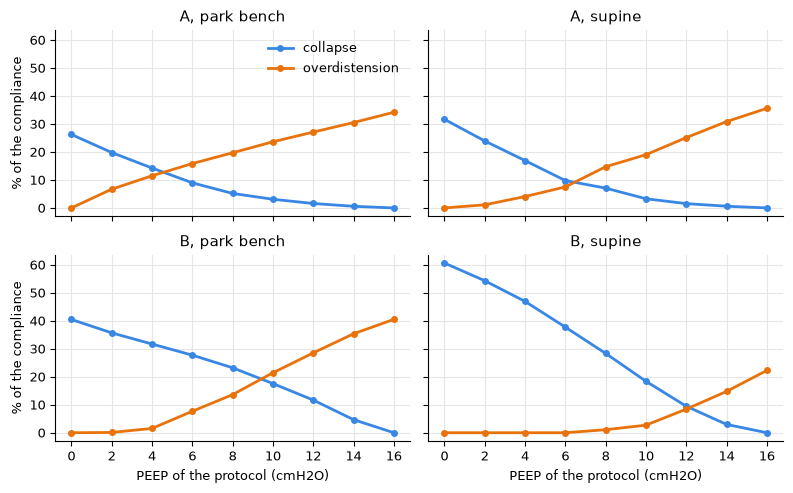

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharex=True, sharey=True)
for ax, ((patient, position), rows) in zip(axes.flat, study["steps"].groupby(["patient_id", "label"])):
    ax.plot(rows.peep_set, rows.collapse, "o-", color=BLUE, lw=2, ms=4, label="collapse")
    ax.plot(rows.peep_set, rows.overdistension, "o-", color=ORANGE, lw=2, ms=4, label="overdistension")
    ax.set_title(f"{patient}, {position.replace('_', ' ')}")
    ax.invert_xaxis()
for ax in axes[1]:
    ax.set_xlabel("PEEP of the protocol (cmH2O)")
for ax in axes[:, 0]:
    ax.set_ylabel("% of the compliance")
axes[0, 0].legend(frameon=False)
fig.tight_layout()

## 5. CSV files

`write_csv()` writes one file per table: UTF-8, comma separated, decimal point, empty cell for a missing value, booleans
as 1 / 0. Here in a temporary folder:

In [15]:
with tempfile.TemporaryDirectory() as folder:
    paths = write_csv(study, folder)
    files = pd.DataFrame({
        name: {"rows": len(pd.read_csv(path)), "columns": pd.read_csv(path, nrows=0).shape[1],
               "KB": round(path.stat().st_size / 1024)}
        for name, path in paths.items()
    }).T
    breaths_csv = pd.read_csv(paths["breaths"])
print("values of is_valid, used, excluded:", sorted(set(breaths_csv[["is_valid", "used", "excluded"]].stack())))
print("longest column name:", max(len(c) for t in study.values() for c in t.columns), "characters")
files

values of is_valid, used, excluded: [0, 1]
longest column name: 39 characters


,rows,columns,KB
recordings,15,29,4
breaths,1552,57,980
steps,36,62,35
settings,332,6,18
log,178,5,20


Reading the files:

```r
library(tidyverse)
breaths <- read_csv("results/breaths.csv")
steps   <- read_csv("results/steps.csv")
```

In SPSS: File > Import Data > CSV Data, with the first row as variable names. In Python: `pd.read_csv()`.